In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import seaborn as sns

In [4]:
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("C:/Users/ELCOT/Downloads/hotel_bookings.csv.zip")

In [7]:
print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

In [8]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(119390, 32)


In [9]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')


In [10]:
print("Data Types:")
print(df.dtypes)

Data Types:
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                 

In [11]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340


In [12]:
num_cols = df.select_dtypes(include=np.number).columns

cat_cols = df.select_dtypes(include='object').columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                    

C:\Users\ELCOT\AppData\Local\Temp\ipykernel_3684\1930801085.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [13]:
df_encoded = pd.get_dummies(
    df,
    columns=['hotel', 'meal', 'market_segment'],
    dtype=int
)

print(df_encoded.head())

   is_canceled  lead_time  arrival_date_year arrival_date_month  \
0            0        342               2015               July   
1            0        737               2015               July   
2            0          7               2015               July   
3            0         13               2015               July   
4            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  children  ...  \
0                        0                     0       2       0.0  ...   
1                        0                     0       2       0.0  ...   
2                      

In [14]:
num_cols = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'adr'
]

print(df[num_cols].head())

   lead_time  stays_in_weekend_nights  stays_in_week_nights  adults  children  \
0        342                        0                     0       2       0.0   
1        737                        0                     0       2       0.0   
2          7                        0                     1       1       0.0   
3         13                        0                     1       1       0.0   
4         14                        0                     2       2       0.0   

    adr  
0   0.0  
1   0.0  
2  75.0  
3  75.0  
4  98.0  


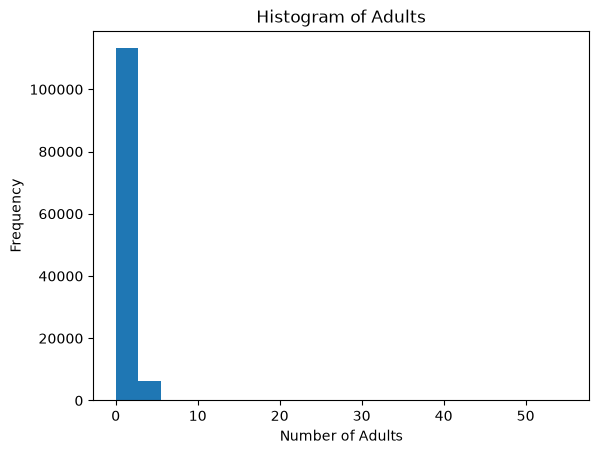

In [21]:
plt.hist(df['adults'], bins=20)

plt.title("Histogram of Adults")
plt.xlabel("Number of Adults")
plt.ylabel("Frequency")

plt.show()

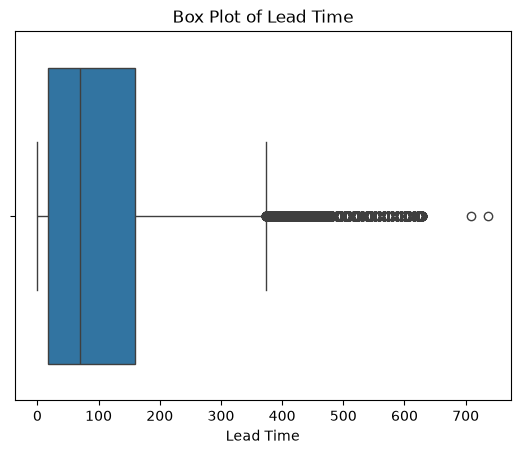

In [19]:
sns.boxplot(x=df['lead_time'])

plt.title("Box Plot of Lead Time")
plt.xlabel("Lead Time")

plt.show()

In [22]:
for col in num_cols:

    skewness = df[col].skew()

    if skewness > 0.5:
        shape = "Positively Skewed"

    elif skewness < -0.5:
        shape = "Negatively Skewed"

    else:
        shape = "Approximately Symmetrical"

    print(col, ":", shape)

lead_time : Positively Skewed
stays_in_weekend_nights : Positively Skewed
stays_in_week_nights : Positively Skewed
adults : Positively Skewed
children : Positively Skewed
adr : Positively Skewed


In [23]:
print("Skewness:")
print(df[num_cols].skew())

Skewness:
lead_time                   1.346550
stays_in_weekend_nights     1.380046
stays_in_week_nights        2.862249
adults                     18.317805
children                    4.112670
adr                        10.530214
dtype: float64


In [24]:
print("Kurtosis:")
print(df[num_cols].kurtosis())

Kurtosis:
lead_time                     1.696449
stays_in_weekend_nights       7.174066
stays_in_week_nights         24.284555
adults                     1352.115116
children                     18.674464
adr                        1013.189851
dtype: float64


In [25]:
print("Descriptive Statistics:")
print(df[num_cols].describe())

Descriptive Statistics:
           lead_time  stays_in_weekend_nights  stays_in_week_nights  \
count  119390.000000            119390.000000         119390.000000   
mean      104.011416                 0.927599              2.500302   
std       106.863097                 0.998613              1.908286   
min         0.000000                 0.000000              0.000000   
25%        18.000000                 0.000000              1.000000   
50%        69.000000                 1.000000              2.000000   
75%       160.000000                 2.000000              3.000000   
max       737.000000                19.000000             50.000000   

              adults       children            adr  
count  119390.000000  119390.000000  119390.000000  
mean        1.856403       0.103886     101.831122  
std         0.579261       0.398555      50.535790  
min         0.000000       0.000000      -6.380000  
25%         2.000000       0.000000      69.290000  
50%         2.0000

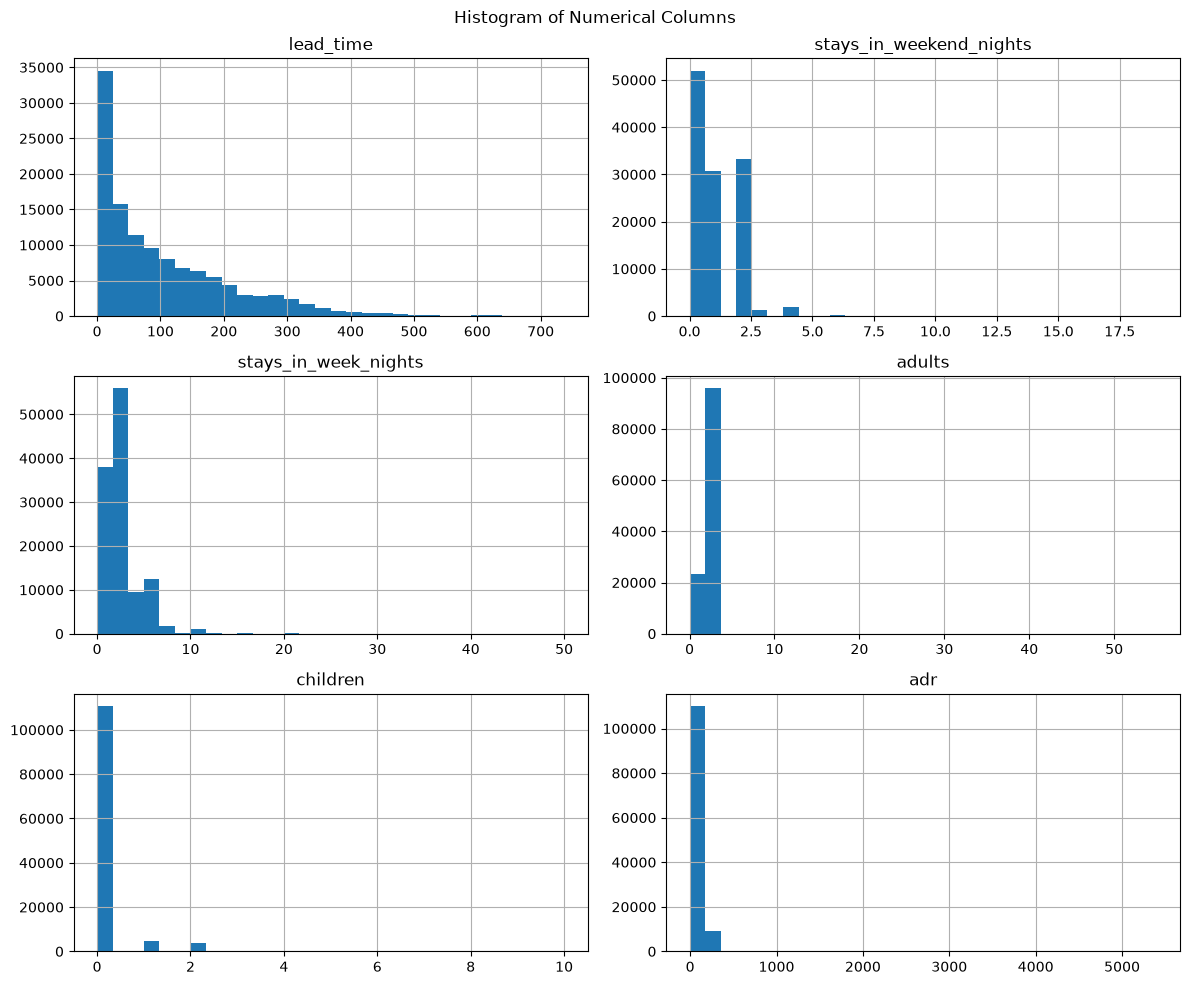

In [26]:
df[num_cols].hist(
    figsize=(12, 10),
    bins=30
)

plt.suptitle("Histogram of Numerical Columns")

plt.tight_layout()
plt.show()

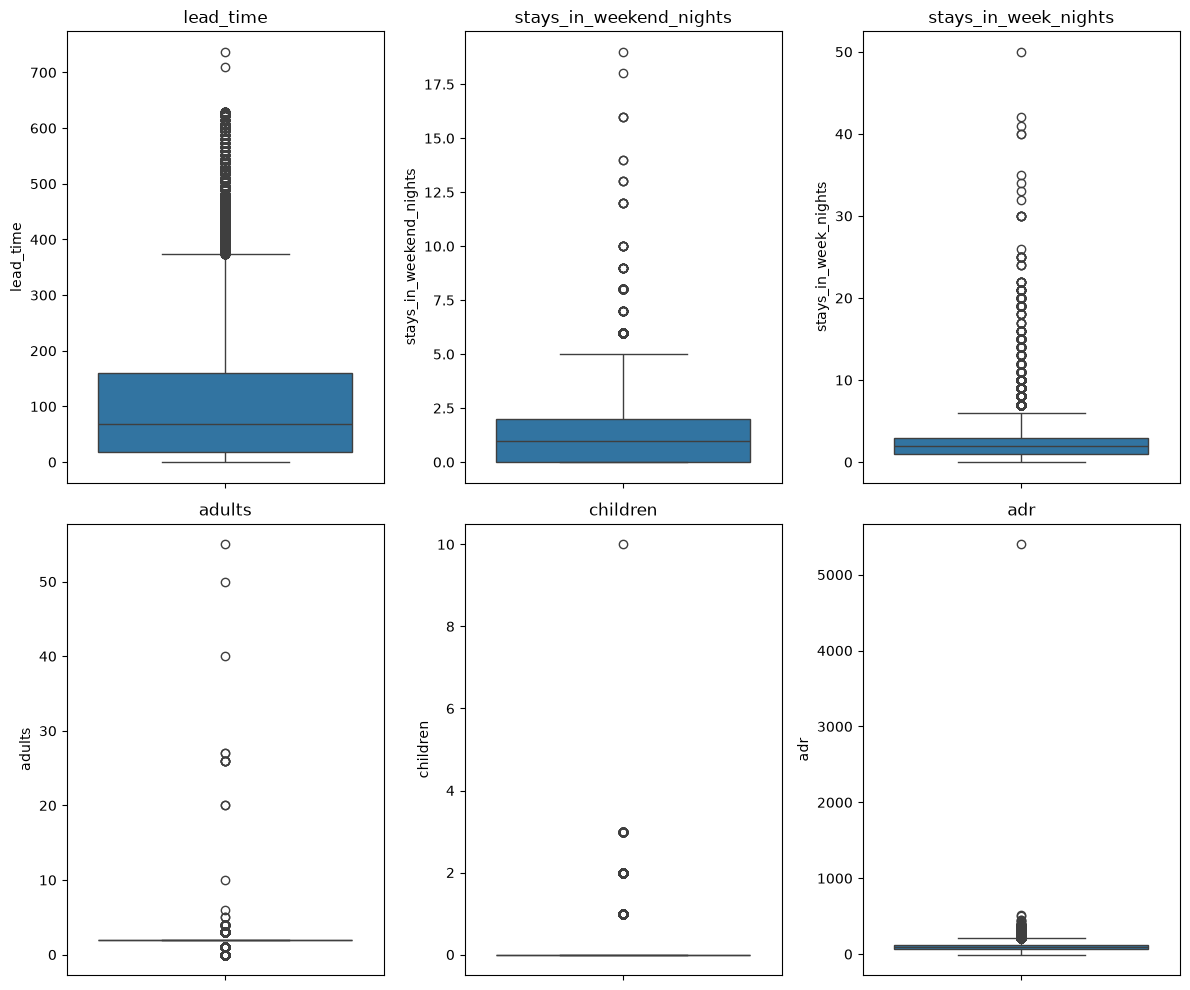

In [27]:
plt.figure(figsize=(12, 10))

for i, col in enumerate(num_cols, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()

In [28]:
result = pd.DataFrame()

result['Skewness'] = df[num_cols].skew()

result['Kurtosis'] = df[num_cols].kurtosis()

print(result)

                          Skewness     Kurtosis
lead_time                 1.346550     1.696449
stays_in_weekend_nights   1.380046     7.174066
stays_in_week_nights      2.862249    24.284555
adults                   18.317805  1352.115116
children                  4.112670    18.674464
adr                      10.530214  1013.189851
